In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set up visual styles for our charts
sns.set_theme(style="whitegrid")

# Define optimized datatypes to prevent RAM crashes
dtype_dict = {
    'order_id': np.int32,
    'user_id': np.int32,
    'eval_set': 'category',
    'order_number': np.int16,
    'order_dow': np.int8,
    'order_hour_of_day': np.int8,
    'days_since_prior_order': np.float32,
    'product_id': np.int32,
    'add_to_cart_order': np.int16,
    'reordered': np.int8,
    'department_id': np.int8,
    'aisle_id': np.int16
}

# Load the datasets with downcasted types
orders = pd.read_csv('../data/raw/orders.csv', dtype=dtype_dict)
prior = pd.read_csv('../data/raw/order_products__prior.csv', dtype=dtype_dict)
products = pd.read_csv('../data/raw/products.csv', dtype=dtype_dict)

print("Data loaded successfully!")
print(f"Total Users: {orders['user_id'].nunique():,}")
print(f"Total Orders: {orders['order_id'].nunique():,}")
print(f"Total Products: {products['product_id'].nunique():,}")

Data loaded successfully!
Total Users: 206,209
Total Orders: 3,421,083
Total Products: 49,688


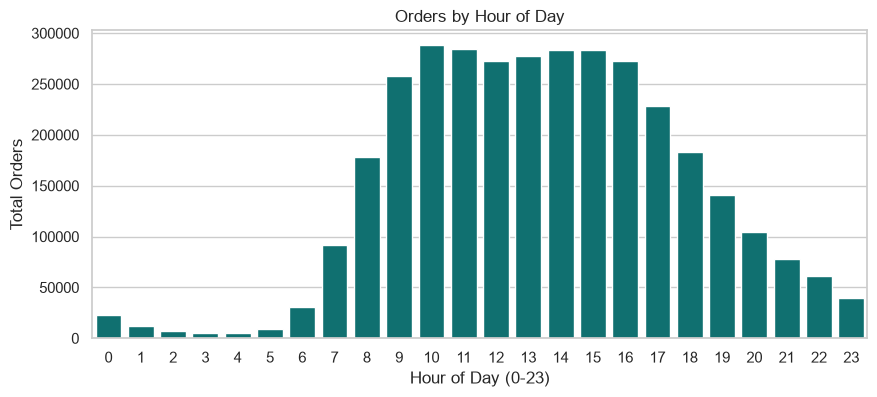

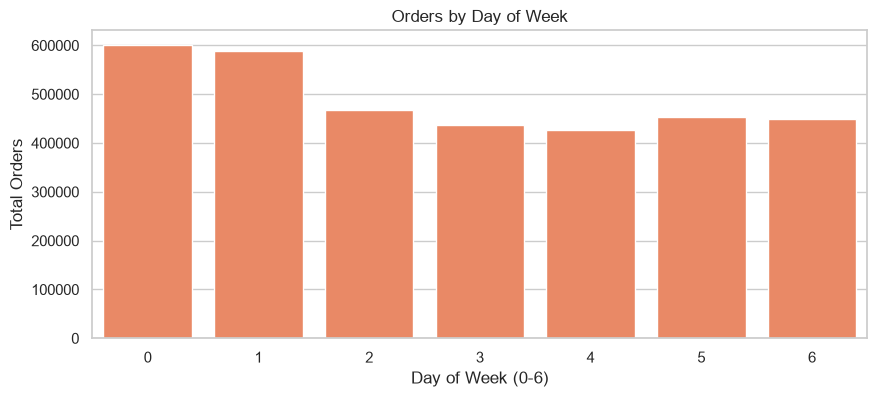

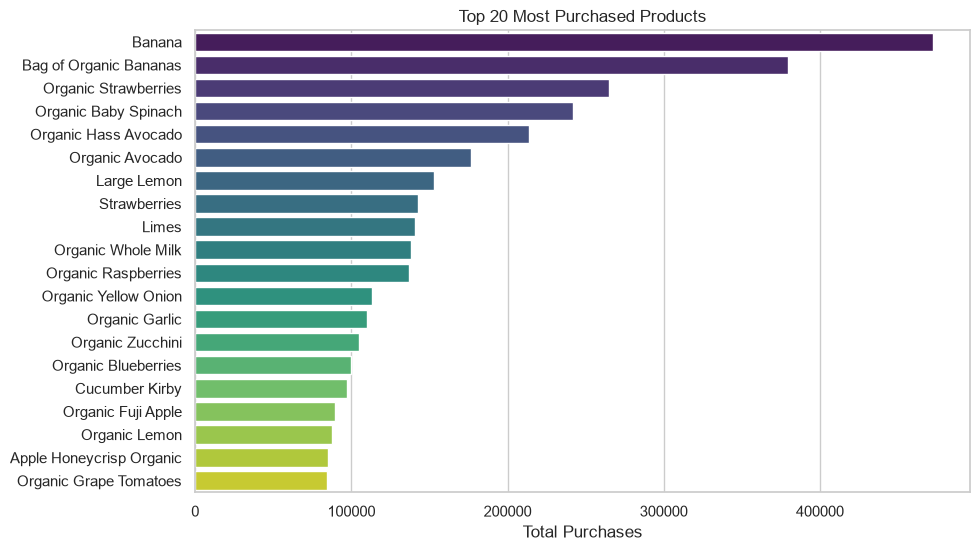

In [3]:
# 1. Orders by Hour of Day
plt.figure(figsize=(10, 4))
sns.countplot(data=orders, x='order_hour_of_day', color='teal')
plt.title('Orders by Hour of Day')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Total Orders')
plt.show()

# 2. Orders by Day of Week
plt.figure(figsize=(10, 4))
sns.countplot(data=orders, x='order_dow', color='coral')
plt.title('Orders by Day of Week')
plt.xlabel('Day of Week (0-6)')
plt.ylabel('Total Orders')
plt.show()

# 3. Top 20 Products
# Merge product names into the prior orders to see actual names instead of IDs
prior_merged = prior.merge(products[['product_id', 'product_name']], on='product_id', how='left')

plt.figure(figsize=(10, 6))
top_products = prior_merged['product_name'].value_counts().head(20)
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, palette='viridis', legend=False)
plt.title('Top 20 Most Purchased Products')
plt.xlabel('Total Purchases')
plt.ylabel('')
plt.show()

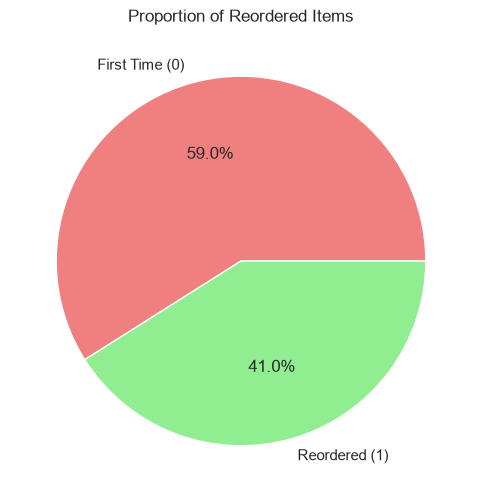

In [4]:
# 4. Reorder Frequency
plt.figure(figsize=(6, 6))
reorder_counts = prior['reordered'].value_counts()
plt.pie(reorder_counts, labels=['First Time (0)', 'Reordered (1)'], autopct='%1.1f%%', colors=['lightcoral', 'lightgreen'])
plt.title('Proportion of Reordered Items')
plt.show()

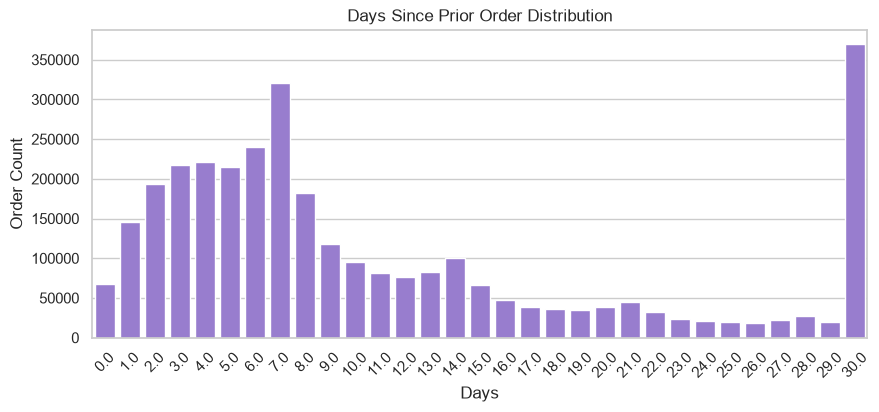

In [5]:
# 5. Days Since Prior Order (Customer Replenishment Cycle)
plt.figure(figsize=(10, 4))
sns.countplot(data=orders, x='days_since_prior_order', color='mediumpurple')
plt.title('Days Since Prior Order Distribution')
plt.xlabel('Days')
plt.ylabel('Order Count')
plt.xticks(rotation=45)
plt.show()


### Week 1 Data Insights:
1. **Peak Ordering Hours:** Order volume surges between 9:00 AM and 5:00 PM, peaking around late morning and early afternoon.
2. **Weekly Cadence:** Orders are heavily concentrated around days 0 and 1 (Sunday/Monday), indicating weekly restocking patterns[cite: 3].
3. **High Reorder Dependency:** Over 59% of purchased items are repeat orders, confirming that a "Buy Again" recommendation feature is essential for user retention[cite: 1, 17].
4. **Dominance of Fresh Produce:** The top 20 most purchased items are overwhelmingly staples and organic perishables (e.g., bananas, strawberries, spinach, milk)[cite: 1, 3].
5. **Replenishment Cycle Spikes:** Order frequency peaks at 7-day intervals and at the 30-day cap, showing clear weekly and monthly habitual buying behavior.